<a href="https://colab.research.google.com/github/nabillahumi/S5-Mesin_Learning/blob/main/UTS/HDBSCAN_Euclidean.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%pip install scikit-learn-extra

In [3]:
import time
import tracemalloc
from pathlib import Path
import hdbscan
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, pairwise_distances
from sklearn.preprocessing import StandardScaler, Normalizer

# Lokasi data/output: berjalan dari root repo, machine_learning, atau experiments.
# Notebook tidak menyediakan __file__.
cwd = Path.cwd().resolve()
BASE_DIR = next(
    (base for parent in (cwd, *cwd.parents)
     for base in (parent / "machine_learning", parent)
     if (base / "experiments").is_dir() and (base / "data").is_dir()),
    None,
)

from pathlib import Path

DATA_PATH = Path("/content/cafes.csv")
FIGURES_DIR = Path("/content/reports/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


In [4]:
# ==============================================================================
# BAGIAN A: LOAD DATA & PREPROCESSING (HDBSCAN)
# ==============================================================================
print("\n" + "="*56)
print("  BAGIAN A: LOAD DATA & PREPROCESSING (HDBSCAN)")
print("="*56)

df = pd.read_csv(DATA_PATH, on_bad_lines="skip")
kolom_fitur = ['latitude', 'longitude', 'rating', 'review_count']
kolom_ada = [k for k in kolom_fitur if k in df.columns]
df_fitur = df[kolom_ada].dropna()

# Standardisasi fitur numerik
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_fitur)

print(f"Data siap | Shape: {X_scaled.shape} | Baris: {len(df_fitur)}")



  BAGIAN A: LOAD DATA & PREPROCESSING (HDBSCAN)
Data siap | Shape: (99, 4) | Baris: 99


In [5]:
# Parameter konfigurasi HDBSCAN
MCS_EUCLID = 4
MS_EUCLID = 2

# --- 1. HDBSCAN EUCLIDEAN ---
print("\n" + "="*56)
print("  HDBSCAN — METRIK: EUCLIDEAN")
print(f"  Parameter: min_cluster_size={MCS_EUCLID}, min_samples={MS_EUCLID}")
print("="*56)

tracemalloc.start()
t_mulai = time.time()

hdb_euclid = hdbscan.HDBSCAN(
    min_cluster_size=MCS_EUCLID, min_samples=MS_EUCLID, metric='euclidean', gen_min_span_tree=True
)
lbl_euclid = hdb_euclid.fit_predict(X_scaled)

t_selesai = time.time()
_, mem_puncak = tracemalloc.get_traced_memory()
tracemalloc.stop()

n_klaster_e = len(set(lbl_euclid)) - (1 if -1 in lbl_euclid else 0)
n_noise_e = int((lbl_euclid == -1).sum())
pct_noise_e = n_noise_e / len(lbl_euclid) * 100
mask_valid_e = lbl_euclid != -1

if mask_valid_e.sum() > 1 and n_klaster_e >= 2:
    sil_euclid = silhouette_score(X_scaled[mask_valid_e], lbl_euclid[mask_valid_e], metric='euclidean')
    sil_e_str = f"{sil_euclid:.4f}"
else:
    sil_euclid = None
    sil_e_str = "N/A (klaster < 2)"

waktu_e = t_selesai - t_mulai
mem_e_kb = mem_puncak / 1024
mem_e_mb = mem_puncak / (1024**2)

print(f"  Jumlah Klaster    : {n_klaster_e}")
print(f"  Titik Noise (-1)  : {n_noise_e} ({pct_noise_e:.1f}%)")
print(f"  Waktu Eksekusi    : {waktu_e:.4f} detik")
print(f"  Memori Puncak     : {mem_e_kb:.2f} KB ({mem_e_mb:.4f} MB)")
print(f"  Silhouette Score  : {sil_e_str}")
print("="*56)



  HDBSCAN — METRIK: EUCLIDEAN
  Parameter: min_cluster_size=4, min_samples=2
  Jumlah Klaster    : 11
  Titik Noise (-1)  : 33 (33.3%)
  Waktu Eksekusi    : 0.0242 detik
  Memori Puncak     : 60.81 KB (0.0594 MB)
  Silhouette Score  : 0.5005



  BAGIAN D: VISUALISASI PCA 2D (HDBSCAN)


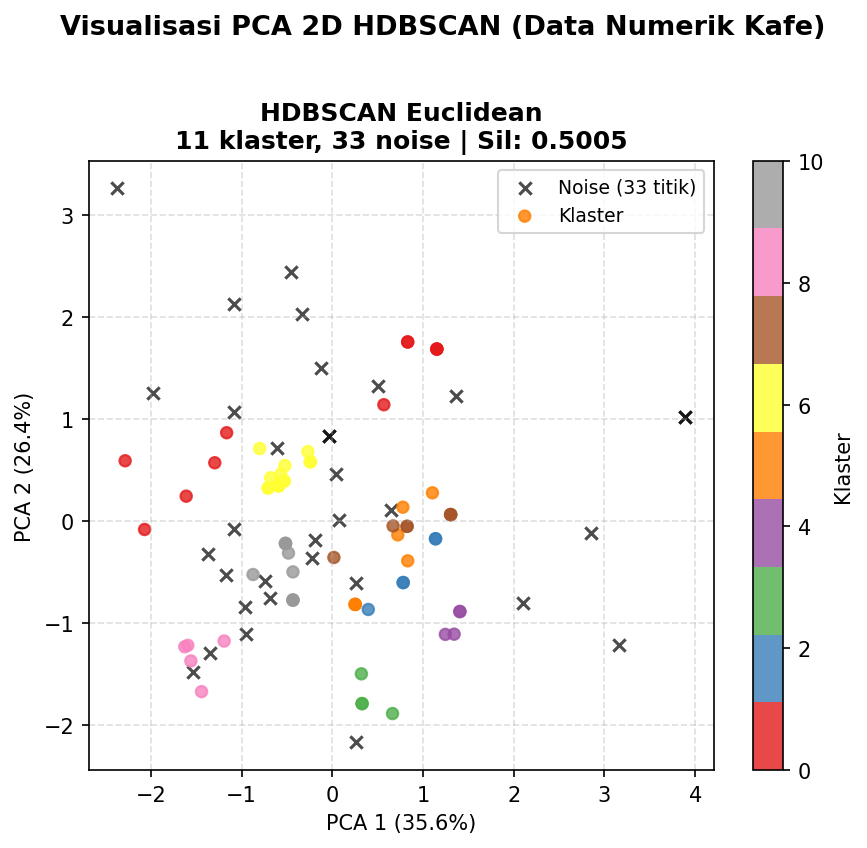

Visualisasi PCA disimpan ke: /content/reports/figures/hdbscan_euclidean_pca_plots.png


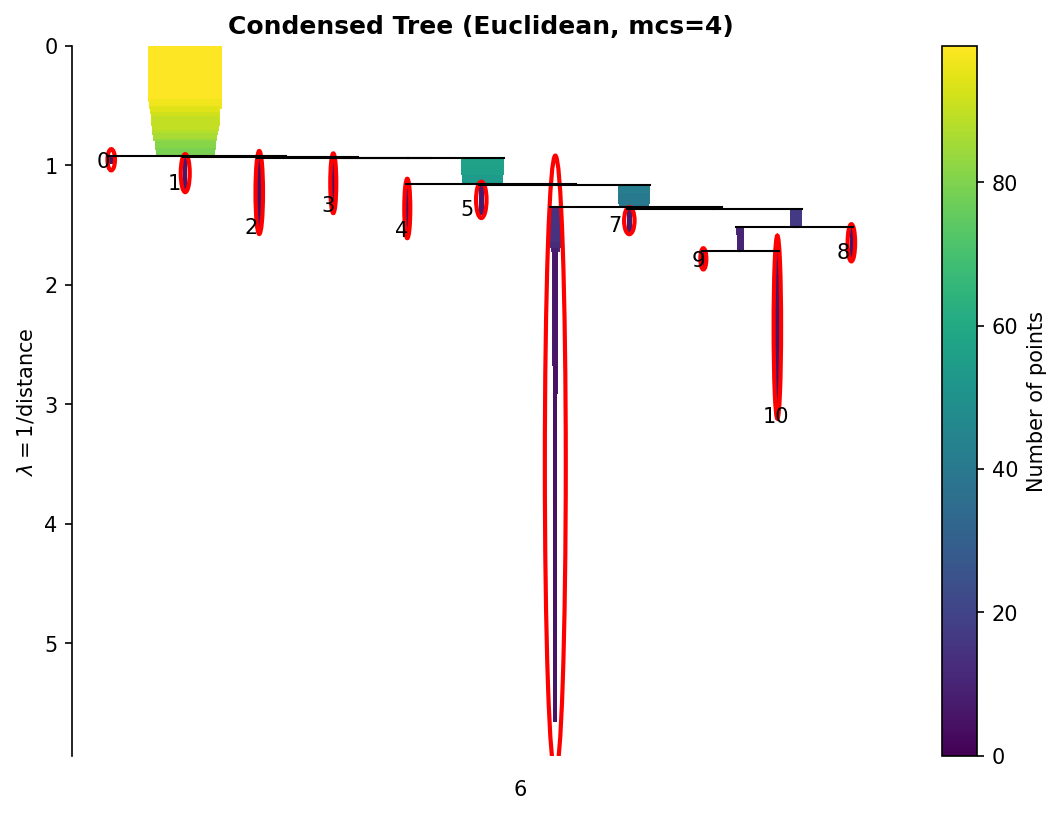

Condensed Tree plot disimpan ke: /content/reports/figures/hdbscan_euclidean_condensed_tree.png


In [6]:
# ==============================================================================
# BAGIAN D: VISUALISASI PCA 2D & CONDENSED CLUSTER TREE
# ==============================================================================
print("\n" + "="*56)
print("  BAGIAN D: VISUALISASI PCA 2D (HDBSCAN)")
print("="*56)

pca = PCA(n_components=2, random_state=42)
X_pca_std = pca.fit_transform(X_scaled)
v1_std, v2_std = pca.explained_variance_ratio_ * 100

fig, ax = plt.subplots(figsize=(6, 5.5), dpi=150)
axes = [ax]

def plot_hdbscan_pca(ax, X_pca_coords, lbls, v1, v2, title):
    mask_noise = lbls == -1
    mask_klaster = ~mask_noise

    # Plot titik noise -> hitam, tanda x
    ax.scatter(X_pca_coords[mask_noise, 0], X_pca_coords[mask_noise, 1],
               c='black', marker='x', s=35, alpha=0.7,
               label=f'Noise ({mask_noise.sum()} titik)')

    # Plot titik klaster -> berwarna
    if mask_klaster.sum() > 0:
        sc = ax.scatter(X_pca_coords[mask_klaster, 0], X_pca_coords[mask_klaster, 1],
                        c=lbls[mask_klaster], cmap='Set1', s=30, alpha=0.8,
                        label='Klaster')
        plt.colorbar(sc, ax=ax, label='Klaster')

    ax.set_title(title, fontweight='bold')
    ax.set_xlabel(f'PCA 1 ({v1:.1f}%)')
    ax.set_ylabel(f'PCA 2 ({v2:.1f}%)')
    ax.legend(fontsize=9)
    ax.grid(True, linestyle='--', alpha=0.4)

plot_hdbscan_pca(axes[0], X_pca_std, lbl_euclid, v1_std, v2_std,
                 f"HDBSCAN Euclidean\n{n_klaster_e} klaster, {n_noise_e} noise | Sil: {sil_e_str}")

plt.suptitle("Visualisasi PCA 2D HDBSCAN (Data Numerik Kafe)", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
hdb_pca_path = FIGURES_DIR / "hdbscan_euclidean_pca_plots.png"
plt.savefig(hdb_pca_path, dpi=150, bbox_inches='tight')
plt.show()
plt.close()
print(f"Visualisasi PCA disimpan ke: {hdb_pca_path}")

fig, ax = plt.subplots(figsize=(7.5, 5.5), dpi=150)
axes = [ax]
# Condensed Tree Plot
hdb_euclid.condensed_tree_.plot(axis=axes[0], select_clusters=True, label_clusters=True)
axes[0].set_title(f"Condensed Tree (Euclidean, mcs={MCS_EUCLID})", fontweight='bold')
axes[0].set_ylabel(r"$\lambda = 1 / \text{distance}$")

plt.tight_layout()
tree_plot_path = FIGURES_DIR / "hdbscan_euclidean_condensed_tree.png"
plt.savefig(tree_plot_path, dpi=150)
plt.show()
plt.close()
print(f"Condensed Tree plot disimpan ke: {tree_plot_path}")


In [7]:
# Dictionary ringkasan performa untuk pelaporan
HDBSCAN_SUMMARY = {
    "euclidean": {
        "algo": "HDBSCAN", "metric": "Euclidean", "param": f"mcs={MCS_EUCLID}, ms={MS_EUCLID}",
        "time": waktu_e, "mem_mb": mem_e_mb, "clusters": n_klaster_e,
        "noise_pct": pct_noise_e, "silhouette": sil_euclid, "labels": lbl_euclid
    }
}
